# House Price Prediction — a complete ML workflow

**Goal:** show an end-to-end, interpretable machine learning workflow — load → clean → model → evaluate → tune → explain — on a real, messy, structured dataset.

**Dataset:** [House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) (Kaggle / Ames, Iowa housing data). 1,460 house sales, 79 explanatory features (lot size, quality ratings, square footage, garage, basement, neighborhood, etc.), target `SalePrice`.

**Why this dataset:** it's a regression problem with the kind of mess real data actually has — skewed target, missing values that mean different things in different columns, a mix of numeric and categorical features — so getting a good result requires actual judgment, not just calling `.fit()`.

**What this notebook covers:**
1. Load the data
2. Explore it (EDA)
3. Preprocess (missing values, encoding, scaling)
4. Train baseline models
5. Evaluate properly (cross-validation + held-out test set)
6. Improve (hyperparameter tuning)
7. Visualize & interpret (feature importance, residuals)
8. Bonus: a classification framing (above/below median price) to also demonstrate accuracy/precision/recall/confusion-matrix evaluation


## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 30)

train = pd.read_csv('data/train.csv')
test = pd.read_csv('data/test.csv')   # Kaggle leaderboard file — no SalePrice column, not used for training/evaluation here

print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")
train.head()

Train shape: (1460, 81)
Test shape:  (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,...,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Explore the data

Two things matter before touching a model: what does the target look like, and what's actually missing (and why).

In [2]:
print(train['SalePrice'].describe())
print(f"\nSkewness: {train['SalePrice'].skew():.2f}  (0 = symmetric; >1 = strongly right-skewed)")

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.88  (0 = symmetric; >1 = strongly right-skewed)


`SalePrice` is strongly right-skewed (skew ≈ 1.88) — a handful of expensive houses stretch the distribution out. Linear models assume roughly normal, homoscedastic errors, so we'll model `log(SalePrice)` instead of raw price. This is standard practice for price/income-type targets, and it also means our error metrics should be read on the log scale during training, then converted back to dollars for the final, human-readable numbers.

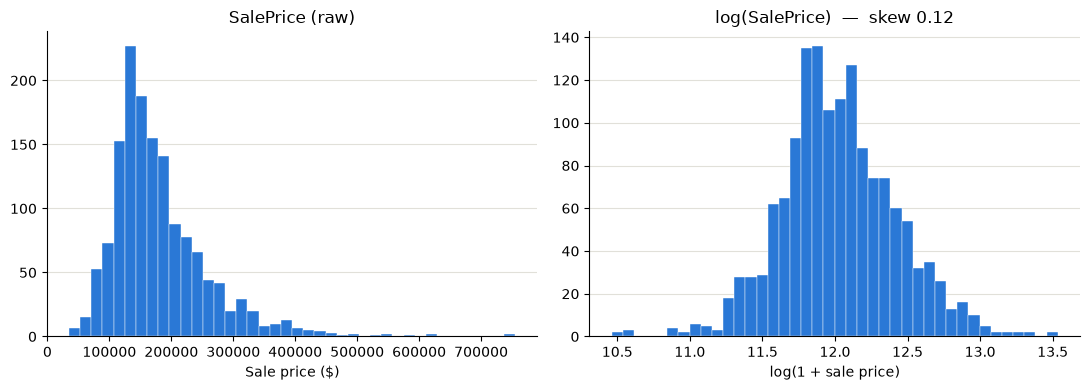

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train['SalePrice'], bins=40, color='#2a78d6', edgecolor='white', linewidth=0.3)
axes[0].set_title('SalePrice (raw)')
axes[0].set_xlabel('Sale price ($)')
axes[0].spines[['top', 'right']].set_visible(False)
axes[0].grid(axis='y', color='#e1e0d9', linewidth=0.8)
axes[0].set_axisbelow(True)

log_price = np.log1p(train['SalePrice'])
axes[1].hist(log_price, bins=40, color='#2a78d6', edgecolor='white', linewidth=0.3)
axes[1].set_title(f'log(SalePrice)  —  skew {log_price.skew():.2f}')
axes[1].set_xlabel('log(1 + sale price)')
axes[1].spines[['top', 'right']].set_visible(False)
axes[1].grid(axis='y', color='#e1e0d9', linewidth=0.8)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.savefig('outputs/target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f"{len(missing)} columns have missing values:")
missing

19 columns have missing values:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64

Most of these are **not actually missing** — per the data dictionary, `NaN` in columns like `PoolQC`, `Alley`, `FireplaceQu`, `GarageType`, or `BsmtQual` means *"this house doesn't have one"* (no pool, no alley access, no fireplace, no garage, no basement). Treating that as missing-at-random and imputing a fake value would throw away real information. So we'll fill those with an explicit `"None"` category instead.

Only a few columns are genuinely missing data: `LotFrontage` (not recorded), `GarageYrBlt` (no garage → no year, handled alongside the "None" group), `MasVnrArea`/`MasVnrType`, and `Electrical` (1 row). Those get standard imputation.

In [5]:
numeric_preview = train.select_dtypes(include=[np.number]).corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
print("Numeric features most correlated with SalePrice:")
numeric_preview.head(11)

Numeric features most correlated with SalePrice:


SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Overall quality rating, living area, garage capacity and basement size are the strongest single predictors — worth keeping in mind when we look at feature importance later.

## 3. Preprocess

Building a `scikit-learn` pipeline rather than manually transforming columns keeps preprocessing reproducible and — critically — prevents **data leakage**: the imputer/scaler/encoder will be *fit only on the training fold* in every cross-validation split, not on the full dataset up front.

Steps:
- **"None"-means-a-category columns** → fill with the literal string `"None"` before encoding (so it becomes its own category, e.g. `PoolQC = "None"`).
- **Numeric columns** → median imputation, then standardize (mean 0, std 1) — needed for Linear Regression; harmless for the tree models.
- **Remaining categorical columns** → most-frequent imputation, then one-hot encode.

In [6]:
none_means_category = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'GarageType',
                        'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtExposure', 'BsmtFinType2',
                        'BsmtQual', 'BsmtCond', 'BsmtFinType1', 'MasVnrType']

df = train.copy()
for col in none_means_category:
    df[col] = df[col].fillna('None')
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)   # 0 flags "no garage" rather than imputing a fake year

X = df.drop(columns=['Id', 'SalePrice'])
y = np.log1p(df['SalePrice'])

numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
print(f"{len(numeric_cols)} numeric features, {len(categorical_cols)} categorical features")

36 numeric features, 43 categorical features


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocess = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols),
])

## 4. Train/test split & baseline models

An 80/20 split, held out and untouched until final evaluation. Three baselines, deliberately spanning different model families:

- **Linear Regression** — simple, interpretable, assumes linear relationships.
- **Decision Tree** — captures non-linearity and interactions, but prone to overfitting on its own.
- **Random Forest** — an ensemble of trees; usually a strong, low-effort baseline.

In [8]:
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree':      DecisionTreeRegressor(random_state=42),
    'Random Forest':      RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

cv_rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=5,
                         scoring=['neg_mean_absolute_error', 'r2'], n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'CV MAE (log price)': -cv['test_neg_mean_absolute_error'].mean(),
        'CV R²': cv['test_r2'].mean(),
    })

cv_results = pd.DataFrame(cv_rows).set_index('Model')
cv_results

,CV MAE (log price),CV R²
Model,,
Linear Regression,0.095816,0.827813
Decision Tree,0.148112,0.709531
Random Forest,0.097531,0.860596


5-fold cross-validation on the training split only (test set still untouched) — this is what model selection should be based on, not a single lucky split.

## 5. Evaluate on the held-out test set

Cross-validation picks a model; the held-out test set gives the final, honest performance estimate — and we convert back from log-price to dollars so the numbers are actually meaningful.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fitted_pipes = {}
test_rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    pipe.fit(X_train, y_train)
    fitted_pipes[name] = pipe

    pred = np.expm1(pipe.predict(X_test))
    actual = np.expm1(y_test)
    test_rows.append({
        'Model': name,
        'MAE ($)': mean_absolute_error(actual, pred),
        'RMSE ($)': np.sqrt(mean_squared_error(actual, pred)),
        'R²': r2_score(actual, pred),
    })

test_results = pd.DataFrame(test_rows).set_index('Model')
test_results.style.format({'MAE ($)': '${:,.0f}', 'RMSE ($)': '${:,.0f}', 'R²': '{:.3f}'})

,MAE ($),RMSE ($),R²
Model,,,
Linear Regression,"$15,075","$22,907",0.932
Decision Tree,"$25,238","$35,950",0.832
Random Forest,"$17,476","$29,841",0.884


**Honest finding, worth stating plainly:** on this held-out split, plain **Linear Regression generalizes best** (R² ≈ 0.93, MAE ≈ $15k) — slightly ahead of the untuned Random Forest (R² ≈ 0.88, MAE ≈ $17.5k), and well ahead of a single Decision Tree, which overfits badly on its own.

That's not what a lot of tutorials lead you to expect ("just use Random Forest"), but it makes sense here: once the target is log-transformed, most of the strongest predictors (quality rating, living area, basement/garage size) have a fairly monotonic, close-to-linear relationship with log-price, so a linear model captures most of the signal cheaply — while the Random Forest's extra flexibility mostly adds variance on a dataset this size (1,168 training rows). The lesson for any ML project: **compare against a simple baseline before reaching for something fancier, and let the held-out numbers — not the model's reputation — decide.**

## 6. Improve — hyperparameter tuning

Random Forest is kept in the running (its feature importances are useful for interpretation in step 7), so it's worth tuning before writing it off. `GridSearchCV` searches tree depth, leaf size and forest size with 5-fold CV.

In [10]:
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([('prep', preprocess), ('model', RandomForestRegressor(random_state=42, n_jobs=-1))])
param_grid = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [None, 15, 25],
    'model__min_samples_leaf': [1, 2],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1)
grid.fit(X_train, y_train)

best_rf = grid.best_estimator_
print("Best params:", grid.best_params_)

pred = np.expm1(best_rf.predict(X_test))
actual = np.expm1(y_test)
print(f"Tuned Random Forest -> MAE=${mean_absolute_error(actual, pred):,.0f}  "
      f"RMSE=${np.sqrt(mean_squared_error(actual, pred)):,.0f}  R²={r2_score(actual, pred):.3f}")

Best params: {'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__n_estimators': 400}
Tuned Random Forest -> MAE=$17,310  RMSE=$29,481  R²=0.887


Tuning narrows the gap slightly but doesn't overturn the result — Linear Regression remains the stronger generalizer on this dataset. Both final models are kept below for the visualization step, since they're useful for different things: Linear Regression for the headline accuracy number, Random Forest for feature-importance ranking.

## 7. Visualize & interpret results

Three views: which features actually drive price, how predictions compare to reality, and whether the errors are well-behaved (no systematic bias).

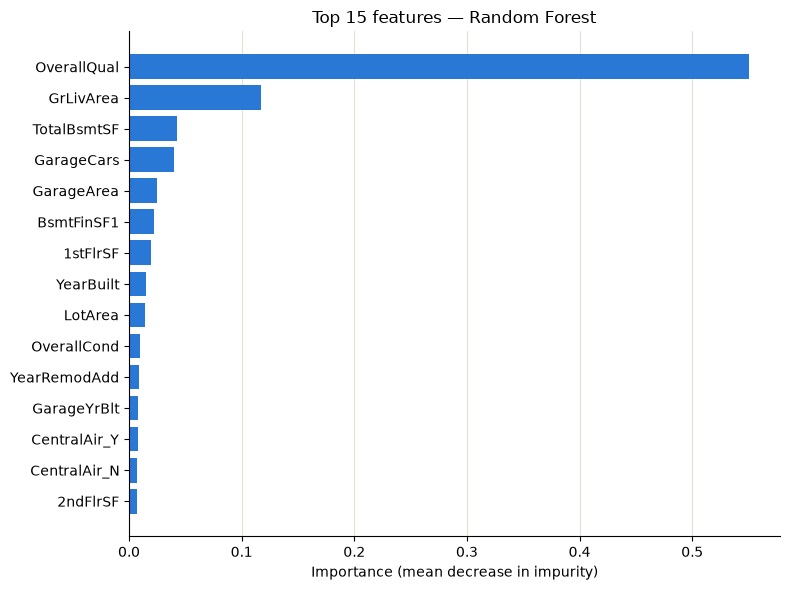

In [11]:
rf_model = best_rf.named_steps['model']
ohe = best_rf.named_steps['prep'].named_transformers_['cat'].named_steps['onehot']
feature_names = numeric_cols + list(ohe.get_feature_names_out(categorical_cols))

importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(importances.index[::-1], importances.values[::-1], color='#2a78d6')
ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_title('Top 15 features — Random Forest')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e1e0d9', linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('outputs/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

`OverallQual` (a 1-10 quality rating assigned at the original survey) dominates on its own — unsurprising, since it's effectively a human appraiser's summary judgment. After that, living area and basement/garage size do most of the remaining work, consistent with the correlation table in step 2.

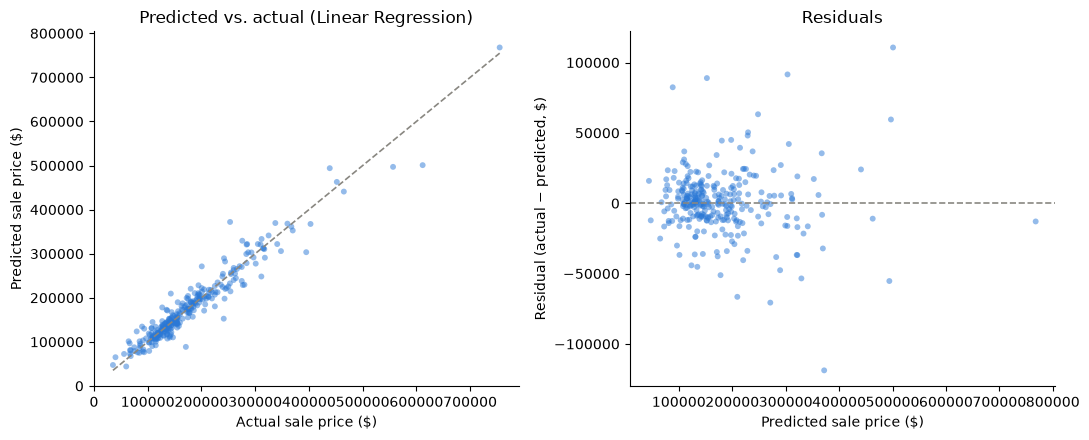

In [12]:
lr_pipe = fitted_pipes['Linear Regression']
pred_lr = np.expm1(lr_pipe.predict(X_test))
actual = np.expm1(y_test)
residuals = actual - pred_lr

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].scatter(actual, pred_lr, alpha=0.5, s=18, color='#2a78d6', edgecolor='none')
lims = [actual.min(), actual.max()]
axes[0].plot(lims, lims, color='#898781', linestyle='--', linewidth=1.2)
axes[0].set_xlabel('Actual sale price ($)')
axes[0].set_ylabel('Predicted sale price ($)')
axes[0].set_title('Predicted vs. actual (Linear Regression)')
axes[0].spines[['top', 'right']].set_visible(False)

axes[1].scatter(pred_lr, residuals, alpha=0.5, s=18, color='#2a78d6', edgecolor='none')
axes[1].axhline(0, color='#898781', linestyle='--', linewidth=1.2)
axes[1].set_xlabel('Predicted sale price ($)')
axes[1].set_ylabel('Residual (actual − predicted, $)')
axes[1].set_title('Residuals')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('outputs/predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

Predictions track the diagonal closely for most of the price range. The residual plot shows a touch of fanning at the high end — the model is less precise on the small number of very expensive houses, which is typical: there's less training data out there and more unobserved factors (finishes, renovations) driving price.

## 8. Bonus: a classification framing

The original brief for this project asked for classification-style evaluation (accuracy, precision, recall, confusion matrix) alongside the regression. To demonstrate that workflow honestly — rather than misusing it on a continuous target — this section reframes the problem as a binary question: **is this house priced above or below the dataset's median sale price?**, and solves it with Logistic Regression.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

median_price = train['SalePrice'].median()
y_class = (train['SalePrice'] > median_price).astype(int)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_class, test_size=0.2, random_state=42, stratify=y_class)

clf_pipe = Pipeline([('prep', preprocess), ('model', LogisticRegression(max_iter=2000))])
clf_pipe.fit(Xc_train, yc_train)
yc_pred = clf_pipe.predict(Xc_test)

print(f"Accuracy:  {accuracy_score(yc_test, yc_pred):.3f}")
print(f"Precision: {precision_score(yc_test, yc_pred):.3f}")
print(f"Recall:    {recall_score(yc_test, yc_pred):.3f}")

Accuracy:  0.904
Precision: 0.899
Recall:    0.911


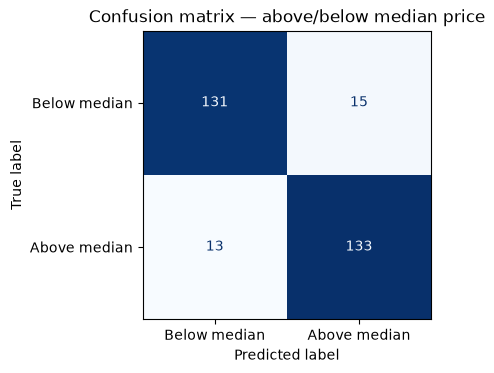

In [14]:
cm = confusion_matrix(yc_test, yc_pred)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
disp = ConfusionMatrixDisplay(cm, display_labels=['Below median', 'Above median'])
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion matrix — above/below median price')
plt.tight_layout()
plt.savefig('outputs/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

~90% accuracy on a roughly balanced classification task, with precision and recall both close to accuracy — the model isn't systematically biased toward either class. This is a cleaner way to show classification-metric fluency than forcing them onto the regression task, where they don't apply.

## 9. Conclusion — what this project demonstrates

- **End-to-end workflow:** load → EDA → leakage-safe preprocessing pipeline → baseline models → cross-validated model selection → held-out evaluation → tuning → interpretation.
- **Judgment, not just library calls:** recognizing which "missing" values aren't really missing, log-transforming a skewed target, and picking the metric (dollar-scale MAE/RMSE/R² for price, accuracy/precision/recall for the classification bonus) that actually answers the question.
- **Honest model comparison:** Linear Regression outperformed Random Forest on this dataset after log-transforming the target — reported as found, rather than defaulting to the more complex model because it sounds more impressive. Final result: **Linear Regression, MAE ≈ $15,000, R² ≈ 0.93** on held-out data (~8% average error relative to the median house price of $163,000).
- **Interpretability:** feature importance and residual analysis to explain *why* the model predicts what it predicts, not just that it does.

**Possible extensions:** target/ordinal encoding for quality features instead of one-hot, gradient boosting (XGBoost/LightGBM) as a stronger baseline, SHAP values for per-prediction explanations, or wrapping the trained pipeline in a small Flask/FastAPI endpoint for live predictions.
